# AnteceDengue — análise exploratória (EDA)

**Regra desta análise:** só entram dados de treino e validação. O conjunto de teste (as últimas 26 semanas do painel) não é inspecionado nem usado para tirar conclusões. O corte é calculado no código (`FIM_EDA`) e as linhas posteriores são descartadas logo após o carregamento.

Para rodar: `jupyter nbconvert --to notebook --execute --inplace notebooks/01_eda.ipynb` (ver README). Os gráficos são salvos em `reports/figuras/eda_*.png`.

In [1]:
import sys
import warnings
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore")

import joblib
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from matplotlib.colors import LogNorm
from sklearn.inspection import permutation_importance

from src import config
from src.evaluate import compute_metrics
from src.features import build_features, feature_columns, load_inputs
from src.labels import apply_thresholds
from src.models import build_model
from src.reporting import AZUL, CINZA, LARANJA, VERDE
from src.search import SCORER
from src.train import locked_split

plt.rcParams.update({
    "figure.dpi": 80, "savefig.dpi": 150, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e5e7eb", "grid.linewidth": 0.6, "font.size": 10,
})
pd.options.display.float_format = "{:.3f}".format
FIG = config.REPORTS_DIR / "figuras"
FIG.mkdir(exist_ok=True)
%matplotlib inline


def salvar(fig, nome):
    fig.tight_layout()
    fig.savefig(FIG / f"eda_{nome}.png", dpi=150)
    plt.show()

## 1. Objetivo e dados

**Objetivo:** prever a classe de risco de dengue (0 = baixo, 1 = médio, 2 = alto) de cada bairro do Recife na semana seguinte (t+1). Esta EDA serve para entender os dados e justificar as decisões de modelagem, sem treinar modelos novos.

**Fontes:**
- Casos: CSVs anuais de dengue do Portal de Dados Abertos do Recife (licença ODbL), 2013 a 2025; uma linha por notificação. Caso = confirmado (`CLASSI_FIN` 10, 11 ou 12; 1 a 4 nos esquemas antigos).
- Temperatura e umidade: InfoDengue (município, geocode 2611606). A API não traz chuva.
- Chuva: Open-Meteo (reanálise ERA5, grade de ~25 km). **É chuva estimada por reanálise, não medição de estação**, e serve como índice relativo (soma só ~0,42 do volume do INMET).

**Período do painel:** 2015-01-04 a 2025-08-17, 94 bairros, uma linha por bairro e semana epidemiológica (começa no domingo). Os anos de 2013 e 2014 ficam fora.

In [2]:
panel, clima = load_inputs()
df = build_features(panel, clima, city=True)
split = locked_split(df)
thr = split.thresholds
FIM_EDA = split.val["week_start"].max() + pd.Timedelta(weeks=1)
dados = pd.concat([split.train, split.val], ignore_index=True)
panel = panel[panel["week_start"] <= FIM_EDA].copy()
clima = clima[(clima["week_start"] <= FIM_EDA) & (clima["week_start"] >= panel["week_start"].min())].copy()
del df
print("Corte da EDA (última semana usada):", FIM_EDA.date())
print("Painel:", panel["bairro"].nunique(), "bairros x", panel["week_start"].nunique(), "semanas =", len(panel), "linhas")
print("Período do painel:", panel["week_start"].min().date(), "a", panel["week_start"].max().date())
print("Treino:", len(split.train), "linhas;", "validação:", len(split.val), "linhas (alvo da validação termina em", FIM_EDA.date(), ")")
print("Total de casos no período da EDA:", int(panel["casos"].sum()))

Corte da EDA (última semana usada): 2025-02-09
Painel: 94 bairros x 528 semanas = 49632 linhas
Período do painel: 2015-01-04 a 2025-02-09
Treino: 46248 linhas; validação: 2444 linhas (alvo da validação termina em 2025-02-09 )
Total de casos no período da EDA: 56174


In [3]:
def tabela_md(caminho, titulo):
    linhas = caminho.read_text(encoding="utf-8").split("\n")
    i = next(k for k, l in enumerate(linhas) if l.strip() == titulo)
    bloco = []
    for l in linhas[i + 1:]:
        if l.startswith("|"):
            bloco.append(l)
        elif bloco:
            break
    cab = [c.strip() for c in bloco[0].strip("|").split("|")]
    corpo = [[c.strip() for c in l.strip("|").split("|")] for l in bloco[2:]]
    return pd.DataFrame(corpo, columns=cab)


funil = tabela_md(config.REPORTS_DIR / "painel_qualidade.md", "## Funil de registros")
display(funil)
bruto = int(funil.iloc[0]["registros"])
final = int(funil.iloc[-1]["registros"])
print(f"Do total lido ({bruto}) sobraram {final} casos no painel: {100 * final / bruto:.1f}%")

,etapa,registros,variação
0,Registros lidos (2013–2025),110640,
1,Após período 2015–2025,106219,-4421
2,Após caso confirmado,61284,-44935
3,Após data válida,61284,0
4,Após bairro válido,60924,-360
5,Após duplicatas,60924,0
6,Após janela do painel (casos no painel),59085,-1839


Do total lido (110640) sobraram 59085 casos no painel: 53.4%


O funil acima vem de `reports/painel_qualidade.md` e descreve a preparação dos dados do painel inteiro (é contagem de registros, não uma análise de resultado). As etapas seguintes da EDA usam apenas o período até `FIM_EDA`.

**Interpretação.** Dos 110.640 registros lidos, 59.085 (53,4%) viraram casos no painel. A maior perda é a definição de caso: 44.935 registros (40,6% do total lido) são descartados ou inconclusivos e saem no filtro de confirmados; o corte de período tira 4.421 (2013–2014) e a janela do painel mais 1.839. Os problemas de limpeza propriamente ditos são pequenos: 360 registros de bairro inválido, só 0,6% dos 61.284 confirmados, e nenhum registro sem data válida.

## 2. Qualidade e tratamento dos dados

In [4]:
problemas = pd.DataFrame([
    ("Formato de data", "Datas em dd/mm/aaaa e aaaa-mm-dd, às vezes misturadas na mesma coluna", "Conversão com dois formatos explícitos; o que não casa vira nulo e o caso usa a data de notificação", "src/data_recife.py"),
    ("Separador e encoding", "Alguns anos usam ';' e outros ','; encoding varia (utf-8-sig / latin-1)", "Detecção automática de encoding e separador; tudo lido como texto", "src/data_recife.py"),
    ("Nomes de colunas", "10 esquemas de colunas diferentes em 13 anos (maiúsculas, minúsculas, nomes novos)", "Mapa de colunas por ano para nomes padronizados", "reports/dados_inspecao.md"),
    ("Códigos com .0", "Classificação final e número de notificação aparecem como '10.0'", "Remoção do '.0' e conversão para inteiro", "src/data_recife.py"),
    ("Bairros mal escritos", "Exemplos: GRAAS, AREAIS, JIQU], PONRO DE PARADA, TAMA, TEJIPI, VASCO", "Normalização (maiúsculas, sem acento), apelidos manuais e correspondência aproximada (corte 0,90): 9 registros corrigidos por apelido", "src/bairros.py, src/bairro_aliases.py"),
    ("Bairros inválidos", "339 nulos, 19 não encontrados, 2 que não são bairro (CENTRO, ZONA RURAL)", "Registros descartados e contados (360 no total)", "reports/painel_qualidade.md"),
    ("Duplicatas", "0 linhas idênticas; 1647 linhas com nu_notificacao repetido mas dados diferentes", "Idênticas removidas (0); as demais mantidas, por serem notificações distintas", "reports/painel_qualidade.md"),
    ("Data de sintomas absurda", "24 casos com data de sintomas mais de 1 ano antes do ano do arquivo", "Usa-se a data de notificação; nenhum caso ficou sem data válida", "reports/painel_qualidade.md"),
    ("Casos não confirmados", "Descartados (5) e inconclusivos (8) dominam a base: 44935 registros saem no filtro", "Só confirmados contam como caso (CASE_CODES)", "src/config.py"),
    ("2013 e 2014", "2013: 3229 linhas; 2014: 1192 linhas, incompleto, e quebraria a série", "Fora do período; painel usa 2015 a 2025", "reports/dados_inspecao.md"),
    ("Cauda truncada de 2025", "Casos recentes ainda sem classificação final deixam as últimas semanas artificialmente baixas", "Painel cortado em PANEL_END = 2025-08-17 (fração de pendentes dentro de 0,27% + 5 pontos percentuais)", "reports/cauda_2025.md"),
    ("Nulos de clima", "25 semanas do painel sem temperatura média nem umidade (InfoDengue)", "Preenchimento só com o passado (forward fill, limite de 2 semanas); o resto vai para o SimpleImputer (mediana) do Pipeline, ajustado só no treino", "src/features.py, src/models.py"),
    ("Chuva", "A API do InfoDengue não traz chuva; o INMET A301 não tem chuva útil de 2022 em diante", "Fonte única Open-Meteo (ERA5), tratada como índice relativo", "reports/clima_qualidade.md"),
], columns=["problema", "evidência", "tratamento", "onde"])
pd.set_option("display.max_colwidth", 140)
display(problemas)

,problema,evidência,tratamento,onde
0,Formato de data,"Datas em dd/mm/aaaa e aaaa-mm-dd, às vezes misturadas na mesma coluna",Conversão com dois formatos explícitos; o que não casa vira nulo e o caso usa a data de notificação,src/data_recife.py
1,Separador e encoding,"Alguns anos usam ';' e outros ','; encoding varia (utf-8-sig / latin-1)",Detecção automática de encoding e separador; tudo lido como texto,src/data_recife.py
2,Nomes de colunas,"10 esquemas de colunas diferentes em 13 anos (maiúsculas, minúsculas, nomes novos)",Mapa de colunas por ano para nomes padronizados,reports/dados_inspecao.md
3,Códigos com .0,Classificação final e número de notificação aparecem como '10.0',Remoção do '.0' e conversão para inteiro,src/data_recife.py
4,Bairros mal escritos,"Exemplos: GRAAS, AREAIS, JIQU], PONRO DE PARADA, TAMA, TEJIPI, VASCO","Normalização (maiúsculas, sem acento), apelidos manuais e correspondência aproximada (corte 0,90): 9 registros corrigidos por apelido","src/bairros.py, src/bairro_aliases.py"
5,Bairros inválidos,"339 nulos, 19 não encontrados, 2 que não são bairro (CENTRO, ZONA RURAL)",Registros descartados e contados (360 no total),reports/painel_qualidade.md
6,Duplicatas,0 linhas idênticas; 1647 linhas com nu_notificacao repetido mas dados diferentes,"Idênticas removidas (0); as demais mantidas, por serem notificações distintas",reports/painel_qualidade.md
7,Data de sintomas absurda,24 casos com data de sintomas mais de 1 ano antes do ano do arquivo,Usa-se a data de notificação; nenhum caso ficou sem data válida,reports/painel_qualidade.md
8,Casos não confirmados,Descartados (5) e inconclusivos (8) dominam a base: 44935 registros saem no filtro,Só confirmados contam como caso (CASE_CODES),src/config.py
9,2013 e 2014,"2013: 3229 linhas; 2014: 1192 linhas, incompleto, e quebraria a série",Fora do período; painel usa 2015 a 2025,reports/dados_inspecao.md


**Limpeza e normalização:** texto padronizado (maiúsculas, sem acentos, sem espaços sobrando), datas convertidas, códigos inteiros, bairros resolvidos contra a tabela oficial e duplicatas tratadas. **Valores ausentes:** datas nulas caem na data de notificação; clima nulo é preenchido só com o passado (forward fill de até 2 semanas, causal) e o restante é imputado pela mediana dentro do Pipeline, ajustada só no treino. **Codificação:** o bairro NÃO entra como variável categórica (nenhum one-hot); o que carrega a identidade do bairro é a média histórica expansiva de casos. A classe de risco é codificada como inteiro ordinal (0, 1, 2). A sazonalidade é codificada por seno e cosseno (abaixo), em vez de número da semana ou mês.

**Interpretação.** A tabela lista 13 problemas e nenhum deles é grande em volume: os descartes por sujeira são 360 registros de bairro inválido, 24 datas de sintoma absurdas e 0 duplicatas idênticas. O que mais pesa para a modelagem não é a limpeza, e sim a cauda truncada de 2025 (cortada em PANEL_END) e as 25 semanas sem temperatura/umidade, que afetam as features de clima. As 1.647 linhas com número de notificação repetido foram mantidas por terem dados diferentes; não verificamos se algumas são o mesmo caso digitado duas vezes, então pode haver pequena dupla contagem.

In [5]:
colunas = feature_columns(city=True)
nulos = (dados[colunas].isna().mean() * 100).sort_values(ascending=False)
print("Features com nulos no treino+validação (% das linhas):")
display(nulos[nulos > 0].to_frame("% nulos"))
print("Semanas do painel (EDA) sem temperatura média:", int(clima["temp_media"].isna().sum()), "de", len(clima))
print("Semanas sem chuva:", int(clima["chuva_mm"].isna().sum()))

Features com nulos no treino+validação (% das linhas):


,% nulos
temp_media_lag1,2.510
temp_media_lag4,2.510
temp_media_lag2,2.510
umid_media_lag4,2.510
umid_media_lag2,2.510
umid_media_lag1,2.510
umid_media_lag8,2.510
temp_media_lag8,2.510


Semanas do painel (EDA) sem temperatura média: 25 de 528
Semanas sem chuva: 0


**Interpretação.** Só as 8 features de temperatura e umidade defasadas têm nulos, e em 2,51% das linhas de treino+validação; chuva e todas as features de casos estão completas. A origem são 25 das 528 semanas (4,7%) sem temperatura e umidade no InfoDengue. O forward fill de até 2 semanas só cobre falhas curtas; o trecho de 9 semanas (set–nov/2017) continua nulo e vai para a mediana no Pipeline, o que mascara o clima real dessas semanas. Com 2,5% das linhas, o efeito esperado no modelo é pequeno.

Distância (seno, cosseno) entre semanas consecutivas, mediana: 0.12
Distância na virada de ano (média): 0.119
Salto no número da semana na virada de ano (52 -> 1): 51
Norma média (seno^2 + cosseno^2): 1.0


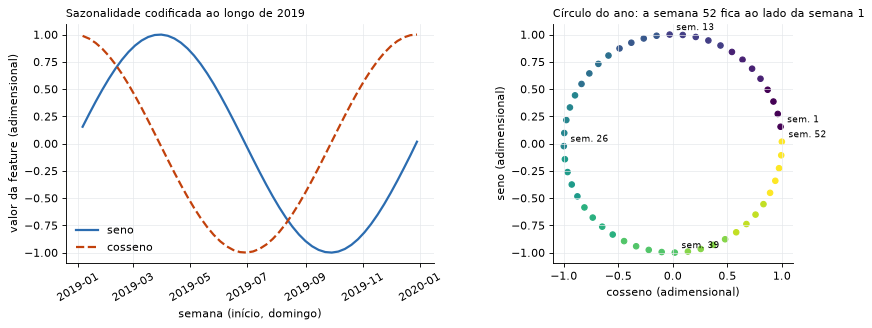

In [6]:
sem = dados[["week_start", "sazon_sin", "sazon_cos"]].drop_duplicates("week_start").sort_values("week_start").reset_index(drop=True)
sem["semana_ano"] = sem["week_start"].dt.isocalendar().week.astype(int)
sem["dist"] = np.hypot(sem["sazon_sin"].diff(), sem["sazon_cos"].diff())
vira = sem["week_start"].dt.year.diff().fillna(0).ne(0)
print("Distância (seno, cosseno) entre semanas consecutivas, mediana:", round(sem["dist"].median(), 3))
print("Distância na virada de ano (média):", round(sem.loc[vira, "dist"].mean(), 3))
print("Salto no número da semana na virada de ano (52 -> 1):", 51)
print("Norma média (seno^2 + cosseno^2):", round((sem["sazon_sin"] ** 2 + sem["sazon_cos"] ** 2).mean(), 3))

um_ano = sem[sem["week_start"].dt.year == 2019]
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ax[0].plot(um_ano["week_start"], um_ano["sazon_sin"], color=AZUL, lw=2, label="seno")
ax[0].plot(um_ano["week_start"], um_ano["sazon_cos"], color=LARANJA, lw=2, ls="--", label="cosseno")
ax[0].set_title("Sazonalidade codificada ao longo de 2019", loc="left", fontsize=10)
ax[0].set_xlabel("semana (início, domingo)")
ax[0].set_ylabel("valor da feature (adimensional)")
ax[0].legend(frameon=False)
ax[0].tick_params(axis="x", rotation=30)
ax[1].scatter(um_ano["sazon_cos"], um_ano["sazon_sin"], c=um_ano["week_start"].dt.month, cmap="viridis", s=24)
for k in (1, 13, 26, 39, 52):
    linha = um_ano.iloc[min(k - 1, len(um_ano) - 1)]
    ax[1].annotate(f"sem. {k}", (linha["sazon_cos"], linha["sazon_sin"]), textcoords="offset points", xytext=(6, 4), fontsize=8)
ax[1].set_aspect("equal")
ax[1].set_title("Círculo do ano: a semana 52 fica ao lado da semana 1", loc="left", fontsize=10)
ax[1].set_xlabel("cosseno (adimensional)")
ax[1].set_ylabel("seno (adimensional)")
salvar(fig, "codificacao_sazonalidade")

**Interpretação.** A distância entre semanas consecutivas no espaço (seno, cosseno) tem mediana 0,120 e, na virada de ano, 0,119: a codificação é contínua, enquanto o número da semana saltaria 51 posições (52 para 1). A norma média é 1,00, confirmando que os pontos ficam no círculo unitário, e o gráfico da direita mostra a semana 52 encostada na semana 1. Isso só garante que a codificação é coerente; não prova que a sazonalidade ajuda a prever (a seção 9 mostra importância por permutação próxima de zero para essas duas features).

## 3. Série temporal de casos da cidade

Limite de epidemia = percentil 90 dos casos semanais da cidade = 311 casos/semana
Mediana semanal: 32; máximo: 1530; média: 106


,início,fim,semanas acima do limite,semana do pico,casos no pico,casos no episódio
0,2015-01-18,2015-05-17,18,2015-03-29,1530,14342
1,2015-10-04,2016-04-03,26,2016-02-14,1129,15934
2,2021-05-09,2021-07-04,9,2021-05-30,613,4223


Casos nos episódios / total: 61.4%


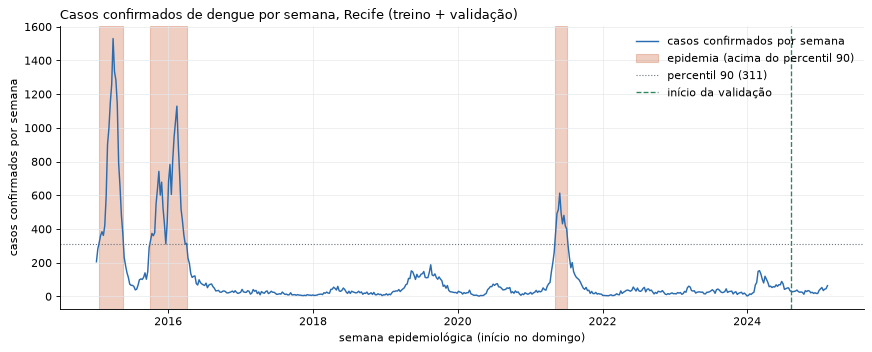

In [7]:
cidade = panel.groupby("week_start")["casos"].sum().to_frame("casos")
limite_epi = cidade["casos"].quantile(0.90)
acima = cidade["casos"] > limite_epi
semanas = cidade.index[acima.values]
episodios = []
ini = prev = semanas[0]
for s in semanas[1:]:
    if (s - prev).days > 14:
        episodios.append((ini, prev))
        ini = s
    prev = s
episodios.append((ini, prev))
linhas = []
for a, b in episodios:
    trecho = cidade.loc[a:b, "casos"]
    linhas.append({"início": a.date(), "fim": b.date(), "semanas acima do limite": int((trecho > limite_epi).sum()),
                   "semana do pico": trecho.idxmax().date(), "casos no pico": int(trecho.max()),
                   "casos no episódio": int(trecho.sum())})
tab_epi = pd.DataFrame(linhas)
print(f"Limite de epidemia = percentil 90 dos casos semanais da cidade = {limite_epi:.0f} casos/semana")
print(f"Mediana semanal: {cidade['casos'].median():.0f}; máximo: {cidade['casos'].max()}; média: {cidade['casos'].mean():.0f}")
display(tab_epi)
print(f"Casos nos episódios / total: {tab_epi['casos no episódio'].sum() / cidade['casos'].sum():.1%}")

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(cidade.index, cidade["casos"], color=AZUL, lw=1.3, label="casos confirmados por semana")
for k, (a, b) in enumerate(episodios):
    ax.axvspan(a - pd.Timedelta(days=3), b + pd.Timedelta(days=3), color=LARANJA, alpha=0.25, label="epidemia (acima do percentil 90)" if k == 0 else None)
ax.axhline(limite_epi, color=CINZA, ls=":", lw=1, label=f"percentil 90 ({limite_epi:.0f})")
ax.axvline(split.val["week_start"].min(), color=VERDE, ls="--", lw=1.2, label="início da validação")
ax.set_title("Casos confirmados de dengue por semana, Recife (treino + validação)", loc="left")
ax.set_xlabel("semana epidemiológica (início no domingo)")
ax.set_ylabel("casos confirmados por semana")
ax.legend(frameon=False)
salvar(fig, "serie_cidade")

**Interpretação.** A série é dominada por três episódios acima do percentil 90 (311 casos/semana): jan–mai/2015 (pico de 1.530 em 2015-03-29, 14.342 casos), out/2015–abr/2016 (pico de 1.129 em 2016-02-14, 15.934 casos) e mai–jul/2021 (pico de 613 em 2021-05-30, 4.223 casos). Esses episódios somam 53 semanas, ou 10% das 528 (o percentil 90 garante isso por construção), mas concentram 61,4% de todos os casos. Fora deles a série é baixa e estável: mediana 32 casos/semana contra média 106 e máximo 1.530. Há bumps menores (2019, início de 2024), mas nenhum chega ao limite. Quase todo o sinal epidêmico do treino vem de apenas 3 episódios.

## 4. Sazonalidade

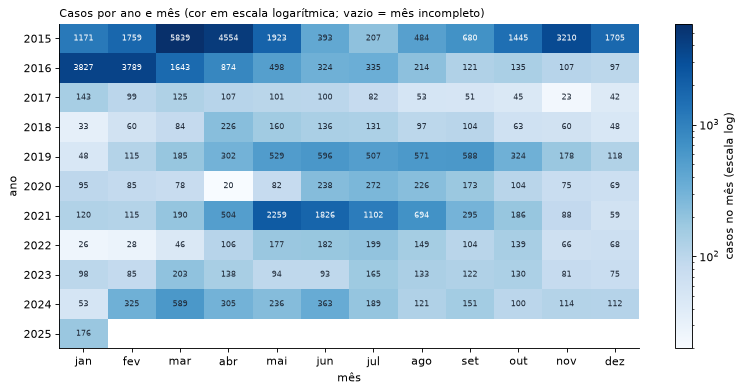

Anos completos usados: [2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024]
Seis maiores meses (ano, mês): casos
ano   mes
2015  3      5839
      4      4554
2016  1      3827
      2      3789
2015  11     3210
2021  5      2259
Mês com menos casos em cada ano completo: {2015: 7, 2016: 12, 2017: 11, 2018: 1, 2019: 1, 2020: 4, 2021: 12, 2022: 1, 2023: 12, 2024: 1}


,% médio dos casos do ano,% mediano,anos em que é o mês de pico
jan,7.445,3.878,2
fev,8.476,5.801,0
mar,11.088,9.931,3
abr,10.158,8.978,1
mai,11.414,9.640,1
jun,11.525,12.486,1
jul,10.244,11.271,2
ago,8.117,8.700,0
set,7.003,6.871,0
out,5.823,5.712,0


Mês de pico por ano: {2015: 3, 2016: 1, 2017: 1, 2018: 4, 2019: 6, 2020: 7, 2021: 5, 2022: 7, 2023: 3, 2024: 3}


In [8]:
cidade["ano"] = cidade.index.year
cidade["mes"] = cidade.index.month
mensal = cidade.pivot_table(index="ano", columns="mes", values="casos", aggfunc="sum")
completo = pd.DataFrame(True, index=mensal.index, columns=mensal.columns)
for ano in mensal.index:
    for mes in mensal.columns:
        fim_mes = pd.Period(year=ano, month=mes, freq="M").end_time
        if fim_mes > FIM_EDA + pd.Timedelta(days=6):
            completo.loc[ano, mes] = False
mensal = mensal.where(completo)
fig, ax = plt.subplots(figsize=(10, 5))
im = ax.imshow(mensal.values.astype(float), cmap="Blues", norm=LogNorm(vmin=max(1, np.nanmin(mensal.values)), vmax=np.nanmax(mensal.values)), aspect="auto")
ax.set_xticks(range(12), ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"])
ax.set_yticks(range(len(mensal)), mensal.index)
for i in range(mensal.shape[0]):
    for j in range(mensal.shape[1]):
        v = mensal.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{int(v)}", ha="center", va="center", fontsize=7, color="white" if v > 600 else "#1f2937")
ax.grid(False)
ax.set_title("Casos por ano e mês (cor em escala logarítmica; vazio = mês incompleto)", loc="left", fontsize=10)
ax.set_xlabel("mês")
ax.set_ylabel("ano")
fig.colorbar(im, ax=ax, label="casos no mês (escala log)")
salvar(fig, "mapa_calor_ano_mes")

anos_completos = [a for a in mensal.index if mensal.loc[a].notna().all()]
parte = mensal.loc[anos_completos]
parte = parte.div(parte.sum(axis=1), axis=0) * 100
resumo_mes = pd.DataFrame({
    "% médio dos casos do ano": parte.mean(),
    "% mediano": parte.median(),
    "anos em que é o mês de pico": parte.idxmax(axis=1).value_counts().reindex(range(1, 13)).fillna(0).astype(int),
})
resumo_mes.index = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]
print("Anos completos usados:", anos_completos)
maiores = mensal.stack().sort_values(ascending=False).head(6)
print("Seis maiores meses (ano, mês): casos")
print(maiores.astype(int).to_string())
print("Mês com menos casos em cada ano completo:", mensal.loc[anos_completos].idxmin(axis=1).to_dict())
display(resumo_mes)
print("Mês de pico por ano:", parte.idxmax(axis=1).to_dict())

**Interpretação.** Os meses mais intensos são 2015-03 (5.839 casos), 2015-04 (4.554), 2016-01 (3.827), 2016-02 (3.789) e 2021-05 (2.259); fora desses anos epidêmicos nenhum mês passa de 600 casos (máximo 596 em 2019-06). Em um ano típico a temporada fica entre março e julho (participação média no ano: jun 11,5%, mai 11,4%, mar 11,1%; dez 3,9%, nov 4,8%), com vale em nov–jan. Mas o mês de pico muda muito entre os 10 anos completos (jan em 2016 e 2017; mar em 2015, 2023 e 2024; jul em 2020 e 2022) e o mês de menor volume é jan em 4 anos e dez em 3. A sazonalidade existe, mas é frouxa e é quebrada pelos anos epidêmicos; com só 10 anos isso é um padrão fraco, não uma regra.

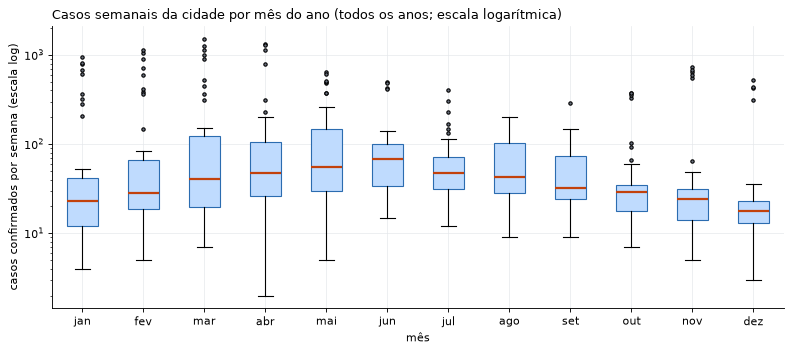

,median,mean,max,count
jan,23.000,118.163,947,49
fev,28.500,156.429,1129,42
mar,41.000,204.136,1530,44
abr,48.000,165.953,1334,43
mai,56.000,134.644,652,45
jun,67.500,101.214,495,42
jul,47.000,70.867,400,45
ago,43.000,63.767,201,43
set,32.000,55.558,290,43
out,29.000,59.356,378,45


Razão entre a maior e a menor mediana mensal: 3.75


In [9]:
fig, ax = plt.subplots(figsize=(10, 4.5))
grupos = [cidade.loc[cidade["mes"] == m, "casos"].values for m in range(1, 13)]
ax.boxplot(grupos, tick_labels=["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"], patch_artist=True,
           boxprops={"facecolor": "#bfdbfe", "edgecolor": AZUL}, medianprops={"color": LARANJA, "lw": 2}, flierprops={"markersize": 3, "markerfacecolor": CINZA})
ax.set_yscale("log")
ax.set_title("Casos semanais da cidade por mês do ano (todos os anos; escala logarítmica)", loc="left")
ax.set_xlabel("mês")
ax.set_ylabel("casos confirmados por semana (escala log)")
salvar(fig, "boxplot_mes")
medianas = cidade.groupby("mes")["casos"].agg(["median", "mean", "max", "count"])
medianas.index = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]
display(medianas)
print("Razão entre a maior e a menor mediana mensal:", round(medianas["median"].max() / medianas["median"].min(), 2))

**Interpretação.** A mediana semanal é maior em jun (67,5 casos) e menor em dez (18), razão de 3,75. A média, porém, é maior em março (204) porque 2015 (máximo 1.530) puxa a cauda; por isso mediana e média contam histórias diferentes. As caixas se sobrepõem muito e o máximo de um mês (1.530) é muito maior que a mediana de qualquer mês, ou seja, a variação entre anos é maior que a variação entre meses. O mês ajuda a ordenar o risco, mas explica pouco sozinho.

## 5. Distribuição por bairro

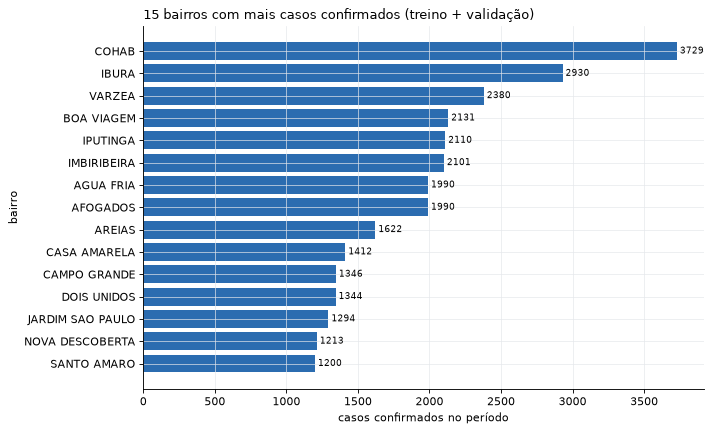

bairro
COHAB         3729
IBURA         2930
VARZEA        2380
BOA VIAGEM    2131
IPUTINGA      2110
Total de casos: 56174 | top 15 somam: 28792 (51.3%)
Maior bairro / mediana dos bairros: 11.2
Bairros com menos de 50 casos: 8


In [10]:
por_bairro = panel.groupby("bairro")["casos"].sum().sort_values(ascending=False)
n_b = len(por_bairro)
top15 = por_bairro.head(15)
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(top15.index[::-1], top15.values[::-1], color=AZUL)
for i, v in enumerate(top15.values[::-1]):
    ax.text(v, i, f" {v}", va="center", fontsize=8)
ax.set_title("15 bairros com mais casos confirmados (treino + validação)", loc="left")
ax.set_xlabel("casos confirmados no período")
ax.set_ylabel("bairro")
salvar(fig, "top15_bairros")
print(por_bairro.head(5).to_string())
print("Total de casos:", int(por_bairro.sum()), "| top 15 somam:", int(top15.sum()), f"({top15.sum() / por_bairro.sum():.1%})")
print("Maior bairro / mediana dos bairros:", round(por_bairro.iloc[0] / por_bairro.median(), 1))
print("Bairros com menos de 50 casos:", int((por_bairro < 50).sum()))

**Interpretação.** Os 15 bairros com mais casos (COHAB 3.729, IBURA 2.930, VARZEA 2.380, BOA VIAGEM 2.131, IPUTINGA 2.110...) somam 28.792 dos 56.174 casos (51,3%). O maior bairro tem 11,2 vezes a mediana dos bairros, e 8 bairros têm menos de 50 casos no período. Os números são contagens brutas, sem dividir pela população (que não temos), então parte da diferença reflete tamanho do bairro e não risco por habitante; não dá para afirmar que COHAB é mais arriscado no sentido per capita.

10% dos bairros (10 de 94) concentram 39.9% dos casos
20% dos bairros (19 de 94) concentram 59.1% dos casos
Metade dos casos está nos 15 bairros com mais casos


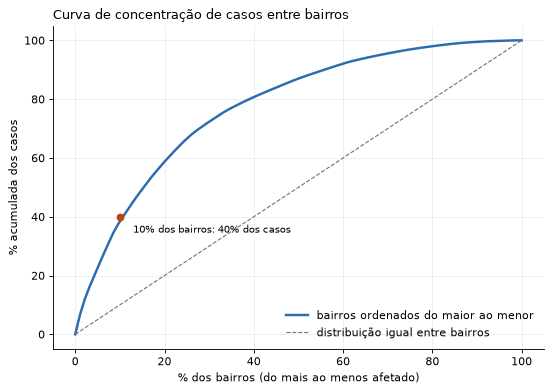

In [11]:
acum = por_bairro.cumsum() / por_bairro.sum()
x = np.arange(1, n_b + 1) / n_b
k10 = int(np.ceil(0.10 * n_b))
k20 = int(np.ceil(0.20 * n_b))
p10, p20 = acum.iloc[k10 - 1], acum.iloc[k20 - 1]
print(f"10% dos bairros ({k10} de {n_b}) concentram {p10:.1%} dos casos")
print(f"20% dos bairros ({k20} de {n_b}) concentram {p20:.1%} dos casos")
print(f"Metade dos casos está nos {int((acum < 0.5).sum() + 1)} bairros com mais casos")
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(np.r_[0, x] * 100, np.r_[0, acum.values] * 100, color=AZUL, lw=2.2, label="bairros ordenados do maior ao menor")
ax.plot([0, 100], [0, 100], color=CINZA, ls="--", lw=1, label="distribuição igual entre bairros")
ax.scatter([10], [p10 * 100], color=LARANJA, zorder=3)
ax.annotate(f"10% dos bairros: {p10:.0%} dos casos", (10, p10 * 100), textcoords="offset points", xytext=(12, -14), fontsize=9)
ax.set_title("Curva de concentração de casos entre bairros", loc="left")
ax.set_xlabel("% dos bairros (do mais ao menos afetado)")
ax.set_ylabel("% acumulada dos casos")
ax.legend(frameon=False, loc="lower right")
salvar(fig, "curva_concentracao")

**Interpretação.** Os 10% de bairros com mais casos (10 de 94) concentram 39,9% dos casos; 20% (19 bairros) concentram 59,1%, e metade dos casos está nos 15 primeiros. Isso é concentração moderada: uma distribuição uniforme daria 10% e 20%, e uma regra 80/20 daria 80% para os 20% de cima, que não é o caso (59,1%). Na prática os casos se espalham por muitos bairros, o que justifica modelar por bairro em vez de só os poucos campeões.

Proporção de bairro-semanas com zero casos: 72.7%
Mediana por bairro: 76.7% | mínimo 22.0% | máximo 99.8%
Por ano (%): {2015: 37.6, 2016: 56.4, 2017: 86.4, 2018: 83.8, 2019: 68.6, 2020: 84.6, 2021: 62.1, 2022: 83.8, 2023: 83.2, 2024: 79.7, 2025: 76.2}
Bairros com mais de 90% das semanas sem caso: 14


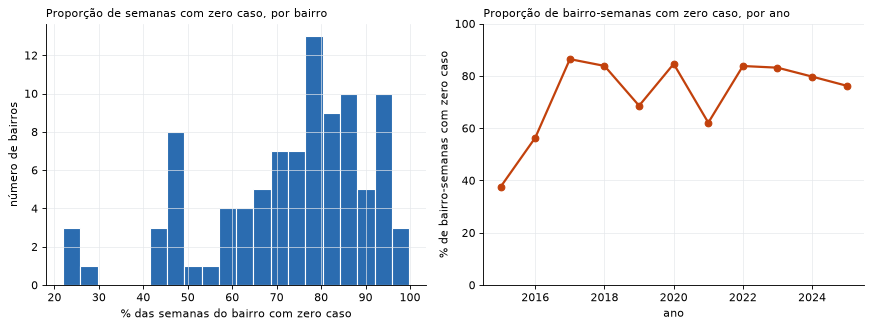

In [12]:
zeros_bairro = panel.assign(zero=panel["casos"].eq(0)).groupby("bairro")["zero"].mean() * 100
zeros_ano = panel.assign(zero=panel["casos"].eq(0), ano=panel["week_start"].dt.year).groupby("ano")["zero"].mean() * 100
print(f"Proporção de bairro-semanas com zero casos: {panel['casos'].eq(0).mean():.1%}")
print(f"Mediana por bairro: {zeros_bairro.median():.1f}% | mínimo {zeros_bairro.min():.1f}% | máximo {zeros_bairro.max():.1f}%")
print("Por ano (%):", zeros_ano.round(1).to_dict())
print(f"Bairros com mais de 90% das semanas sem caso: {(zeros_bairro > 90).sum()}")
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ax[0].hist(zeros_bairro, bins=20, color=AZUL, edgecolor="white")
ax[0].set_title("Proporção de semanas com zero caso, por bairro", loc="left", fontsize=10)
ax[0].set_xlabel("% das semanas do bairro com zero caso")
ax[0].set_ylabel("número de bairros")
ax[1].plot(zeros_ano.index, zeros_ano.values, color=LARANJA, lw=2, marker="o")
ax[1].set_title("Proporção de bairro-semanas com zero caso, por ano", loc="left", fontsize=10)
ax[1].set_xlabel("ano")
ax[1].set_ylabel("% de bairro-semanas com zero caso")
ax[1].set_ylim(0, 100)
salvar(fig, "zeros")

**Interpretação.** 72,7% das combinações bairro-semana têm zero caso; por bairro a mediana é 76,7%, variando de 22,0% a 99,8%, e 14 bairros têm mais de 90% das semanas sem caso. Por ano a fração vai de 37,6% (2015) e 56,4% (2016) a 86,4% (2017) e 83–85% em 2018, 2020, 2022 e 2023. A série por bairro é muito inflada de zeros e isso depende do ano: a classe baixo (casos = 0) deve ocupar cerca de 73% das linhas, o que bate com os 73,0% medidos no treino na seção 7. É também a razão de o quantil 0,60 dar limiar 0.

## 6. Clima x casos (correlação cruzada)

Para cada variável de clima, correlação entre o clima na semana t−k e os casos da cidade na semana t, com k de 0 a 12 semanas. Usa-se Spearman (a série de casos é muito assimétrica). **Cuidados:** correlação não é causalidade; clima e casos compartilham sazonalidade, então parte da correlação é só calendário; poucas epidemias grandes (2015, 2016, 2021) dominam o resultado; a chuva é índice relativo de reanálise ERA5, não medição; e a faixa cinza (±2/√n) é ingênua porque ignora a autocorrelação das séries.

Spearman, período todo (n = 528 , faixa ingênua ± 0.087 )


,temp_media,umid_media,chuva_mm
0,-0.206,0.140,0.128
1,-0.198,0.157,0.162
2,-0.173,0.154,0.180
3,-0.144,0.159,0.177
4,-0.118,0.157,0.181
5,-0.093,0.147,0.197
6,-0.055,0.133,0.197
7,-0.032,0.131,0.210
8,-0.006,0.118,0.217
9,0.035,0.093,0.206


Spearman, só 2017 em diante


,temp_media,umid_media,chuva_mm
0,-0.420,0.261,0.191
1,-0.412,0.288,0.235
2,-0.380,0.288,0.262
3,-0.339,0.295,0.251
4,-0.304,0.300,0.257
5,-0.270,0.290,0.277
6,-0.221,0.277,0.275
7,-0.190,0.276,0.299
8,-0.151,0.261,0.309
9,-0.090,0.225,0.295


temp_media: maior |r| no período todo em k=0 (r=-0.206); desde 2017 em k=0 (r=-0.420)
umid_media: maior |r| no período todo em k=3 (r=0.159); desde 2017 em k=4 (r=0.300)
chuva_mm: maior |r| no período todo em k=8 (r=0.217); desde 2017 em k=8 (r=0.309)


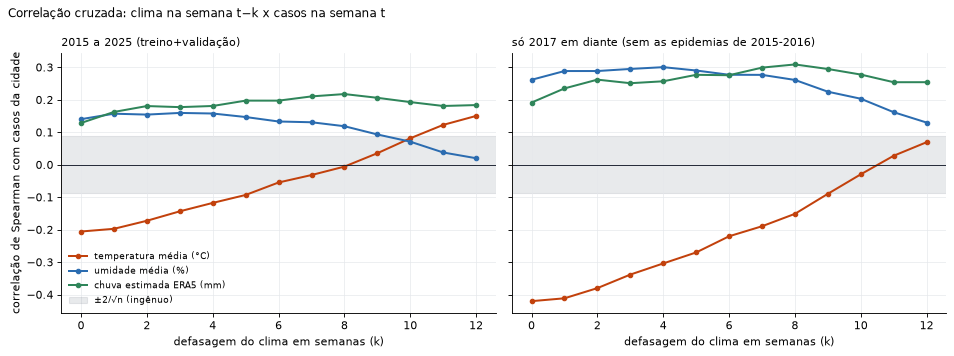

In [13]:
m = cidade[["casos"]].join(clima.set_index("week_start")[["temp_media", "umid_media", "chuva_mm"]])
variaveis = {"temp_media": "temperatura média (°C)", "umid_media": "umidade média (%)", "chuva_mm": "chuva estimada ERA5 (mm)"}
lags = range(0, 13)


def correlacoes(base):
    out = {}
    for v in variaveis:
        out[v] = [base["casos"].corr(base[v].shift(k), method="spearman") for k in lags]
    return pd.DataFrame(out, index=list(lags))


cc_todos = correlacoes(m)
cc_sem1516 = correlacoes(m[m.index.year >= 2017])
n_obs = m["casos"].notna().sum()
faixa = 2 / np.sqrt(n_obs)
print("Spearman, período todo (n =", n_obs, ", faixa ingênua ±", round(faixa, 3), ")")
display(cc_todos)
print("Spearman, só 2017 em diante")
display(cc_sem1516)
for v in variaveis:
    k = int(cc_todos[v].abs().idxmax())
    k2 = int(cc_sem1516[v].abs().idxmax())
    print(f"{v}: maior |r| no período todo em k={k} (r={cc_todos[v][k]:.3f}); desde 2017 em k={k2} (r={cc_sem1516[v][k2]:.3f})")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
cores = {"temp_media": LARANJA, "umid_media": AZUL, "chuva_mm": VERDE}
for eixo, tab, titulo in ((ax[0], cc_todos, "2015 a 2025 (treino+validação)"), (ax[1], cc_sem1516, "só 2017 em diante (sem as epidemias de 2015-2016)")):
    for v, nome in variaveis.items():
        eixo.plot(list(lags), tab[v], marker="o", ms=4, lw=1.8, color=cores[v], label=nome)
    eixo.axhline(0, color="#111827", lw=0.8)
    eixo.axhspan(-faixa, faixa, color=CINZA, alpha=0.15, label="±2/√n (ingênuo)")
    eixo.set_title(titulo, loc="left", fontsize=10)
    eixo.set_xlabel("defasagem do clima em semanas (k)")
ax[0].set_ylabel("correlação de Spearman com casos da cidade")
ax[0].legend(frameon=False, fontsize=8)
fig.suptitle("Correlação cruzada: clima na semana t−k x casos na semana t", x=0.01, ha="left", fontsize=11)
salvar(fig, "correlacao_cruzada")

**Interpretação.** As correlações são fracas: o maior |ρ| de Spearman no período todo é 0,217 (chuva, k=8), 0,206 (temperatura, k=0 e negativa) e 0,159 (umidade, k=3); sem 2015–2016 sobem para 0,309 (chuva, k=8), 0,420 (temperatura, k=0, negativa) e 0,300 (umidade, k=4). As curvas são planas: a chuva varia só de 0,18 a 0,22 entre k=4 e k=12, então o melhor defasamento de 8 semanas não é um pico nítido e não deve ser lido como o tempo exato entre chuva e casos. A temperatura negativa no lag 0 provavelmente reflete só o calendário (meses mais frescos coincidem com a temporada de casos), não um efeito direto. Correlação não é causalidade, o clima é municipal e a chuva é índice relativo ERA5; o achado é fraco e ambíguo.

## 7. Rótulos

Limiares (quantis 0.6 e 0.85 dos casos t+1 no treino): (0.0, 1.0)
Regra: baixo = casos <= 0; médio = casos <= 1; alto = acima de 1


,treino (n),treino (%),validação (n),validação (%)
baixo,33765,73.009,2005,82.038
medio,5774,12.485,255,10.434
alto,6709,14.507,184,7.529


Distribuição dos casos t+1 por bairro-semana no treino (% ; 6 = 6 ou mais):


,%
target_casos,
0.000,73.009
1.000,12.485
2.000,4.770
3.000,2.629
4.000,1.507
5.000,0.997
6.000,4.603


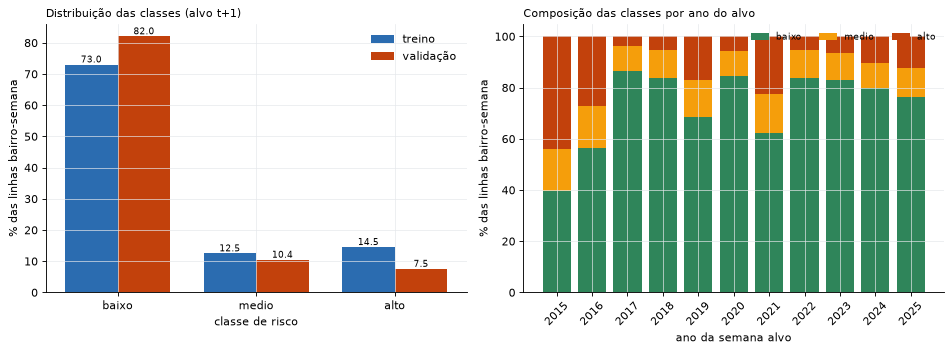

,baixo,medio,alto
ano_alvo,,,
2015,39.461,16.526,44.013
2016,56.383,16.551,27.066
2017,86.431,9.855,3.713
2018,83.838,10.966,5.196
2019,68.597,14.546,16.858
2020,84.615,9.554,5.831
2021,62.111,15.282,22.606
2022,83.797,11.047,5.155
2023,83.159,10.518,6.323


In [14]:
y_tr = apply_thresholds(split.train["target_casos"], thr)
y_va = apply_thresholds(split.val["target_casos"], thr)
nomes = config.CLASSES
dist = pd.DataFrame({
    "treino (n)": [int((y_tr == i).sum()) for i in range(3)],
    "treino (%)": [100 * (y_tr == i).mean() for i in range(3)],
    "validação (n)": [int((y_va == i).sum()) for i in range(3)],
    "validação (%)": [100 * (y_va == i).mean() for i in range(3)],
}, index=nomes)
print(f"Limiares (quantis {config.Q_MID} e {config.Q_HIGH} dos casos t+1 no treino): {thr}")
print("Regra: baixo = casos <= %g; médio = casos <= %g; alto = acima de %g" % (thr[0], thr[1], thr[1]))
display(dist)
valores = split.train["target_casos"].clip(upper=6).value_counts(normalize=True).sort_index() * 100
print("Distribuição dos casos t+1 por bairro-semana no treino (% ; 6 = 6 ou mais):")
display(valores.to_frame("%"))

dados_t = dados.assign(classe=apply_thresholds(dados["target_casos"], thr), ano_alvo=(dados["week_start"] + pd.Timedelta(weeks=1)).dt.year)
por_ano = pd.crosstab(dados_t["ano_alvo"], dados_t["classe"], normalize="index") * 100
por_ano.columns = nomes

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
largura = 0.38
pos = np.arange(3)
ax[0].bar(pos - largura / 2, dist["treino (%)"], largura, color=AZUL, label="treino")
ax[0].bar(pos + largura / 2, dist["validação (%)"], largura, color=LARANJA, label="validação")
for i in range(3):
    ax[0].text(i - largura / 2, dist["treino (%)"].iloc[i], f"{dist['treino (%)'].iloc[i]:.1f}", ha="center", va="bottom", fontsize=8)
    ax[0].text(i + largura / 2, dist["validação (%)"].iloc[i], f"{dist['validação (%)'].iloc[i]:.1f}", ha="center", va="bottom", fontsize=8)
ax[0].set_xticks(pos, nomes)
ax[0].set_title("Distribuição das classes (alvo t+1)", loc="left", fontsize=10)
ax[0].set_xlabel("classe de risco")
ax[0].set_ylabel("% das linhas bairro-semana")
ax[0].legend(frameon=False)
base = np.zeros(len(por_ano))
for classe, cor in zip(nomes, (VERDE, "#f59e0b", LARANJA)):
    ax[1].bar(por_ano.index.astype(str), por_ano[classe], bottom=base, color=cor, label=classe)
    base = base + por_ano[classe].values
ax[1].set_title("Composição das classes por ano do alvo", loc="left", fontsize=10)
ax[1].set_xlabel("ano da semana alvo")
ax[1].set_ylabel("% das linhas bairro-semana")
ax[1].tick_params(axis="x", rotation=45)
ax[1].legend(frameon=False, fontsize=8, ncol=3)
salvar(fig, "rotulos_classes")
display(por_ano)

**Interpretação.** Os limiares do treino são 0 e 1 caso: baixo = 0 casos, médio = 1 caso e alto = 2 ou mais. As classes são 73,0% / 12,5% / 14,5% no treino e 82,0% / 10,4% / 7,5% na validação, então a validação tem bem menos alto. A composição muda muito entre anos: alto é 44,0% em 2015 e 27,1% em 2016, mas só 3,7% em 2017, 5,2% em 2018 e 5,2% em 2022. Os 14,5% de alto do treino são inflados por 2015–2016, e como alto significa só 2+ casos no bairro-semana, ele indica atividade local e não necessariamente surto. Métricas de validação e teste não são comparáveis entre si por causa dessa diferença de distribuição.

## 8. Persistência

Autocorrelação da série da cidade (lags 1 a 12): [0.974, 0.929, 0.867, 0.798, 0.723, 0.646, 0.573, 0.507, 0.454, 0.409, 0.373, 0.343]
Correlação casos_t x casos_t+1 por bairro-semana: Spearman 0.593; Pearson em log1p 0.780
P(casos_t+1 = 0 | casos_t = 0) = 87.0%


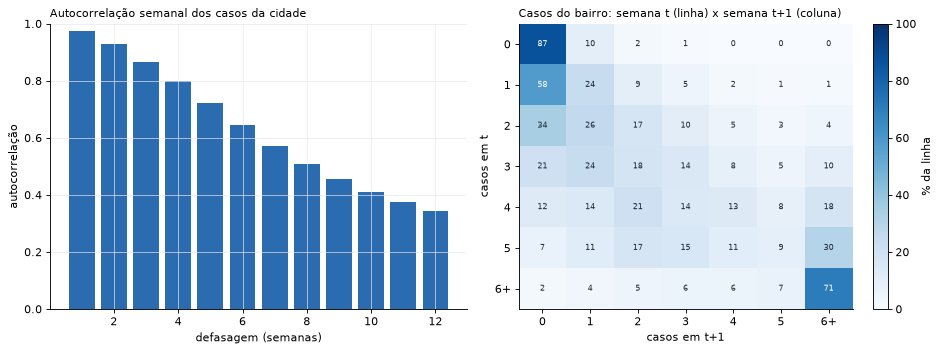

In [15]:
acf = [cidade["casos"].autocorr(lag=k) for k in range(1, 13)]
print("Autocorrelação da série da cidade (lags 1 a 12):", [round(float(a), 3) for a in acf])
ct = pd.crosstab(dados["casos_t"].clip(upper=6), dados["target_casos"].clip(upper=6), normalize="index") * 100
rho_s = dados["casos_t"].corr(dados["target_casos"], method="spearman")
rho_p = np.log1p(dados["casos_t"]).corr(np.log1p(dados["target_casos"]))
print(f"Correlação casos_t x casos_t+1 por bairro-semana: Spearman {rho_s:.3f}; Pearson em log1p {rho_p:.3f}")
print(f"P(casos_t+1 = 0 | casos_t = 0) = {ct.loc[0, 0]:.1f}%")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].bar(range(1, 13), acf, color=AZUL)
ax[0].set_title("Autocorrelação semanal dos casos da cidade", loc="left", fontsize=10)
ax[0].set_xlabel("defasagem (semanas)")
ax[0].set_ylabel("autocorrelação")
ax[0].set_ylim(0, 1)
im = ax[1].imshow(ct.values, cmap="Blues", aspect="auto", vmin=0, vmax=100)
ax[1].set_xticks(range(7), [str(i) if i < 6 else "6+" for i in range(7)])
ax[1].set_yticks(range(7), [str(i) if i < 6 else "6+" for i in range(7)])
for i in range(7):
    for j in range(7):
        ax[1].text(j, i, f"{ct.values[i, j]:.0f}", ha="center", va="center", fontsize=7, color="white" if ct.values[i, j] > 55 else "#1f2937")
ax[1].grid(False)
ax[1].set_title("Casos do bairro: semana t (linha) x semana t+1 (coluna)", loc="left", fontsize=10)
ax[1].set_xlabel("casos em t+1")
ax[1].set_ylabel("casos em t")
fig.colorbar(im, ax=ax[1], label="% da linha")
salvar(fig, "persistencia")

**Interpretação.** A autocorrelação da série da cidade é 0,974 no lag 1, 0,798 no lag 4, 0,507 no lag 8 e 0,343 no lag 12; ela está inflada pelas ondas epidêmicas (a série não é estacionária), mas mostra que a semana seguinte é quase igual à atual. No nível bairro-semana a correlação entre casos em t e t+1 é 0,593 (Spearman) e 0,780 (Pearson em log1p), e quando casos_t = 0 em 87,0% das vezes casos_t+1 também é 0. No mapa de calor a massa na diagonal só aparece nos extremos (0 caso: 87% repetem; 6 ou mais: 71%); nas contagens intermediárias ela se dispersa (com 3 casos, só 14% repetem 3 e 21% voltam a 0).

,baixo,medio,alto
baixo,86.993,9.728,3.279
medio,57.963,23.640,18.397
alto,17.391,16.254,66.355


Persistência: F1-macro treino 0.591; validação 0.558
Recall por classe na validação: baixo 0.906, médio 0.227, alto 0.533
Fração de linhas em que a classe de t+1 é igual à de t: 76.2%


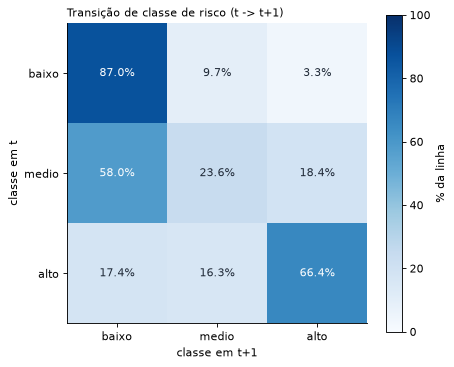

In [16]:
classe_t = apply_thresholds(dados["casos_t"], thr)
classe_t1 = apply_thresholds(dados["target_casos"], thr)
trans = pd.crosstab(pd.Series(classe_t, name="classe em t"), pd.Series(classe_t1, name="classe em t+1"), normalize="index") * 100
trans.index = nomes
trans.columns = nomes
display(trans)
pers_tr = compute_metrics(apply_thresholds(split.train["target_casos"], thr), apply_thresholds(split.train["casos_t"], thr))
pers_va = compute_metrics(y_va, apply_thresholds(split.val["casos_t"], thr))
print(f"Persistência: F1-macro treino {pers_tr['f1_macro']:.3f}; validação {pers_va['f1_macro']:.3f}")
print(f"Recall por classe na validação: baixo {pers_va['recall_baixo']:.3f}, médio {pers_va['recall_medio']:.3f}, alto {pers_va['recall_alto']:.3f}")
acc = (classe_t == classe_t1).mean()
print(f"Fração de linhas em que a classe de t+1 é igual à de t: {acc:.1%}")

fig, ax = plt.subplots(figsize=(5.8, 4.8))
im = ax.imshow(trans.values, cmap="Blues", vmin=0, vmax=100)
ax.set_xticks(range(3), nomes)
ax.set_yticks(range(3), nomes)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{trans.values[i, j]:.1f}%", ha="center", va="center", color="white" if trans.values[i, j] > 55 else "#1f2937")
ax.grid(False)
ax.set_title("Transição de classe de risco (t -> t+1)", loc="left", fontsize=10)
ax.set_xlabel("classe em t+1")
ax.set_ylabel("classe em t")
fig.colorbar(im, ax=ax, label="% da linha")
salvar(fig, "transicao_classes")

**Interpretação.** A classe se repete em 76,2% das linhas. A persistência é forte para baixo (87,0% ficam baixo) e razoável para alto (66,4%), mas fraca para médio: só 23,6% ficam médio, 58,0% caem para baixo e 18,4% sobem para alto. Isso dá à persistência F1-macro de 0,591 no treino e 0,558 na validação (recall: baixo 0,906, médio 0,227, alto 0,533). Como baixo é a classe dominante e estável, o baseline já acerta muito; o espaço para um modelo está sobretudo na classe médio. O RandomForest só-treino tem F1-macro 0,599 na validação, +0,041 sobre a persistência.

## 9. Importância de features do modelo final

O modelo final é o RandomForest otimizado do experimento 03, salvo em `models/best_model.joblib` (reajustado em treino+validação, 27 features). O arquivo `reports/importancia_rf.csv` é do RandomForest padrão do experimento 02 (21 features), então aqui a importância é recalculada a partir do modelo salvo. Para uma medida menos enviesada, a importância por permutação é calculada na **validação** com o mesmo RandomForest ajustado só no treino (o modelo salvo já viu a validação).

Top 12 por impureza (modelo salvo) e permutação (queda do F1-macro na validação):


,impureza,permutacao,perm_desvio,familia
casos_mm4,0.176,0.046,0.009,casos do bairro
casos_mm8,0.159,0.034,0.008,casos do bairro
casos_t,0.112,0.013,0.007,casos do bairro
casos_media_hist,0.073,0.019,0.005,casos do bairro
casos_lag1,0.070,0.000,0.002,casos do bairro
casos_lag2,0.054,-0.003,0.002,casos do bairro
casos_lag3,0.037,0.000,0.001,casos do bairro
cidade_total_t,0.035,-0.002,0.001,cidade (total do município)
cidade_lag1,0.030,-0.002,0.001,cidade (total do município)
tendencia,0.028,-0.002,0.002,casos do bairro


,impureza,permutacao,n_features
familia,,,
casos do bairro,0.709,0.106,8
cidade (total do município),0.134,-0.011,6
umidade,0.049,-0.011,4
temperatura,0.048,-0.008,4
chuva,0.035,-0.007,3
sazonalidade,0.025,-0.004,2


F1-macro da validação do RF só-treino: 0.599


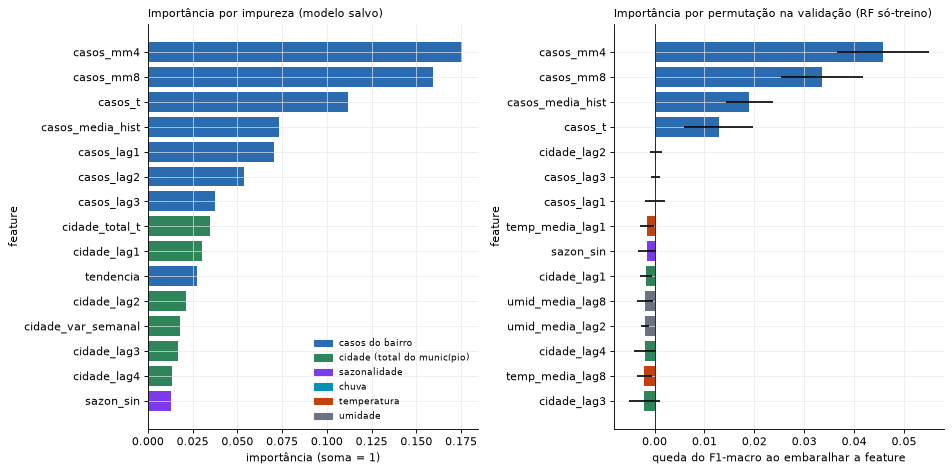

In [17]:
meta = json.loads(config.MODEL_META_PATH.read_text(encoding="utf-8"))
modelo = joblib.load(config.MODEL_PATH)
feats = meta["features"]
imp = pd.Series(modelo.named_steps["clf"].feature_importances_, index=feats, name="impureza").sort_values(ascending=False)

y_tr_full = apply_thresholds(split.train["target_casos"], thr)
rf_treino = build_model("rf", meta["best_params"]).fit(split.train[feats], y_tr_full)
perm = permutation_importance(rf_treino, split.val[feats], y_va, scoring=SCORER, n_repeats=10, random_state=config.SEED, n_jobs=1)
perm_s = pd.Series(perm.importances_mean, index=feats, name="permutacao")
perm_sd = pd.Series(perm.importances_std, index=feats)


def familia(f):
    if f.startswith("cidade"):
        return "cidade (total do município)"
    if f.startswith("casos") or f == "tendencia":
        return "casos do bairro"
    if f.startswith("sazon"):
        return "sazonalidade"
    if f.startswith("chuva"):
        return "chuva"
    if f.startswith("temp"):
        return "temperatura"
    return "umidade"


tab_imp = pd.concat([imp, perm_s, perm_sd.rename("perm_desvio")], axis=1)
tab_imp["familia"] = [familia(f) for f in tab_imp.index]
tab_imp = tab_imp.sort_values("impureza", ascending=False)
print("Top 12 por impureza (modelo salvo) e permutação (queda do F1-macro na validação):")
display(tab_imp.head(12))
fam = tab_imp.groupby("familia")[["impureza", "permutacao"]].sum().sort_values("impureza", ascending=False)
fam["n_features"] = tab_imp.groupby("familia").size()
display(fam)
print("F1-macro da validação do RF só-treino:", round(float(SCORER(rf_treino, split.val[feats], y_va)), 3))

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
top = tab_imp.head(15)
cor_f = {"casos do bairro": AZUL, "cidade (total do município)": VERDE, "sazonalidade": "#7c3aed", "chuva": "#0891b2", "temperatura": LARANJA, "umidade": CINZA}
ax[0].barh(top.index[::-1], top["impureza"][::-1], color=[cor_f[f] for f in top["familia"][::-1]])
ax[0].set_title("Importância por impureza (modelo salvo)", loc="left", fontsize=10)
ax[0].set_xlabel("importância (soma = 1)")
ax[0].set_ylabel("feature")
top_p = tab_imp.sort_values("permutacao", ascending=False).head(15)
ax[1].barh(top_p.index[::-1], top_p["permutacao"][::-1], xerr=top_p["perm_desvio"][::-1], color=[cor_f[f] for f in top_p["familia"][::-1]])
ax[1].axvline(0, color="#111827", lw=0.8)
ax[1].set_title("Importância por permutação na validação (RF só-treino)", loc="left", fontsize=10)
ax[1].set_xlabel("queda do F1-macro ao embaralhar a feature")
ax[1].set_ylabel("feature")
from matplotlib.patches import Patch
ax[0].legend(handles=[Patch(color=c, label=f) for f, c in cor_f.items()], frameon=False, fontsize=8, loc="lower right")
salvar(fig, "importancia_features")

**Interpretação.** Pela impureza (modelo salvo), as features de casos do bairro somam 0,709 (8 features), a cidade 0,134 (6), umidade 0,049, temperatura 0,048, chuva 0,035 e sazonalidade 0,025; as maiores são casos_mm4 (0,176), casos_mm8 (0,159) e casos_t (0,112). Pela permutação na validação (queda do F1-macro) só quatro features contam: casos_mm4 (0,046), casos_mm8 (0,034), casos_media_hist (0,019) e casos_t (0,013); clima, cidade e sazonalidade ficam em torno de zero ou levemente negativos (somas por família entre -0,004 e -0,011, dentro do ruído). Ressalvas: features correlacionadas (médias móveis e lags) dividem a importância; a impureza favorece variáveis contínuas com muitos cortes (por isso clima aparece com 0,132 no total mesmo sem efeito na permutação); e a validação é uma janela de 26 semanas de baixa atividade, onde o clima pode importar menos do que em surtos. As features da cidade deram +0,007 de F1 na ablação da CV, mas aqui contribuem ~0: o ganho é pequeno e ambíguo.

## 10. Conclusões e limitações

### Cinco achados principais
1. **Poucos surtos concentram os casos.** Três episódios (2015, 2015–2016 e 2021) somam 61,4% dos 56.174 casos em 53 de 528 semanas (10%); fora deles a mediana é 32 casos/semana na cidade.
2. **Os dados por bairro são inflados de zeros.** 72,7% das combinações bairro-semana têm zero caso; os limiares de risco ficam em 0 e 1, e as classes são 73,0% / 12,5% / 14,5% no treino e 82,0% / 10,4% / 7,5% na validação.
3. **A persistência é um baseline forte.** A classe se repete em 76,2% das linhas (baixo 87,0%, alto 66,4%, médio só 23,6%); F1-macro da persistência: 0,591 no treino e 0,558 na validação.
4. **O clima tem relação fraca e ambígua com os casos.** O maior |ρ| de Spearman é 0,217 no período todo (0,420 em módulo desde 2017, para temperatura em k=0, negativa); a chuva não tem pico nítido (0,18 a 0,22 entre k=4 e 12).
5. **O sinal do modelo vem do histórico recente de casos.** Pela permutação na validação: casos_mm4 0,046, casos_mm8 0,034, casos_media_hist 0,019 e casos_t 0,013; clima, cidade e sazonalidade ~0.

Outros pontos: 10% dos bairros concentram 39,9% dos casos; a temporada típica vai de março a julho, mas o mês de pico varia entre os 10 anos completos.

### Limitações
- **Poucos episódios epidêmicos:** só 3 surtos no treino; o modelo aprende pouco sobre dinâmica epidêmica e o treino (14,5% alto) difere da validação (7,5%).
- **Janela de validação curta e calma:** 26 semanas, com 82,0% de baixo; conclusões sobre a importância do clima podem não valer em surtos.
- **Sem população por bairro:** as contagens são brutas; não se pode falar em risco per capita.
- **Clima único para a cidade:** todos os bairros recebem o mesmo clima, então ele não explica diferenças entre bairros; a chuva é reanálise ERA5 (índice relativo), e 25 semanas de temperatura/umidade estão imputadas.
- **Alto = 2 ou mais casos no bairro-semana** (limiares 0 e 1): mede atividade local, não surto.
- **Correlação não é causalidade:** a sazonalidade comum entre clima e casos explica parte das correlações.
- **O conjunto de teste não foi inspecionado** nesta análise; nada aqui fala sobre fevereiro a agosto de 2025.

### Onde a interpretação é menos segura
- O sinal negativo da temperatura (-0,42 desde 2017) é provavelmente sazonal, mas esta análise não separa isso de um efeito real.
- O melhor defasamento de 8 semanas da chuva é uma curva plana; não deve ser usado como número mágico.
- O ganho das features da cidade (+0,007 na CV) não aparece na permutação da validação.